# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  Jurre van Woerden <br>
**Title of the experiment:**  Bepaling van de constante van Boltzmann <br>
**Starting date:**  
**Expected enddate:**  23-11-2026 <br>
**Partner:**  Pim kroes <br>
**Goal of the experiment:**  De constante van Boltzmann bepalen via diode-metingen <br>
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [7]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 


# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [96]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!

#Weerstand R1, R2, R3, zie  opstelling
R1 = 33076
u_R1 = 5

R2 = 994.50
u_R2 = 0.05

R3 = 329.55
u_R3 = 0.05

#het data.csv bestand laden met de data
data = np.loadtxt('Data/data.csv', delimiter=',', encoding='utf-8-sig')

#De data omzetten naar numpy arrays
U_bron_raw = data[0, :]
u_U_bron = 0.05

#Onzekerheden zijn gebaseerd op hoe nauwkeurig wij konden aflezen
U_R1_raw = data[1, :]
u_U_R1 = 0.05 * U_R1_raw




**Observations:** Bij hogere waardes zijn de metingen een stuk minder accuraat <br>
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


Text(0, 0.5, 'I (A)')

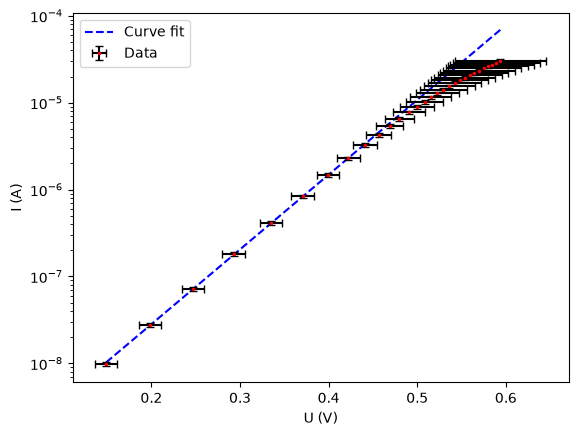

In [105]:
#Data processing and analysis:

#De stroom over de diode en de onzekerheid hier van
I_diode = U_R1_raw / R1
u_I_diode = I_diode * np.sqrt((u_U_R1 / U_R1_raw)**2 + (u_R1 / R1)**2)

#De spanning over de diode met de onzekerheid
U_diode = (U_bron_raw * R3 / (R2 + R3)) - U_R1_raw

#Onzekerheid van de spanning moet met partiële afgeleides gebeuren
dU_dUbron = R3 / (R2 + R3)
dU_dUR1   = -1
dU_dR2    = -(U_bron_raw * R3) / (R2 + R3)**2
dU_dR3    = (U_bron_raw * R2) / (R2 + R3)**2

#Dus de totale onzekerheid:
u_U_diode = np.sqrt((dU_dUbron * u_U_bron) **2 + (dU_dUR1 * u_U_R1) ** 2 + (dU_dR2 * u_R2) ** 2 + (dU_dR3 * u_R3) ** 2)


#Waardes boven de 0.6 zijn zeer instabiel 
mask_plot = (U_diode >= 0.1) & (U_diode <= 0.6)

U_diode_plot = U_diode[mask_plot]
I_diode_plot = I_diode[mask_plot]

u_U_diode_plot = u_U_diode[mask_plot]
u_I_diode_plot = u_I_diode[mask_plot]

#Waardes boven de 0.45 zijn niet linear, mogelijke redenen worden beschreven in de discussie.
mask_fit = (U_diode >= 0.1) & (U_diode <= 0.45)

U_diode_fit = U_diode[mask_fit]
I_diode_fit = I_diode[mask_fit]

u_I_diode_fit = u_I_diode[mask_fit]

#de functie die we gaan fitten in de vorm ae^bx
def func_fit(x, a, b):
    return a * np.exp(x * b)

values, covariance = curve_fit(func_fit, U_diode_fit, I_diode_fit, sigma=u_I_diode_fit, absolute_sigma=True)

#het plotten van de grafieken en de opmaak hiervan
plt.plot(U_diode_plot, func_fit(U_diode_plot, *values), 'b--', label='Curve fit')
plt.errorbar(U_diode_plot, I_diode_plot, xerr=u_U_diode_plot, yerr=u_I_diode_plot, label='Data', fmt='r.', markersize=3, ecolor='black', capsize=3)
plt.legend()
plt.yscale("log")
plt.xlabel("U (V)")
plt.ylabel("I (A)")




In [104]:
#Data processing and analysis:
#Het berekenen van de constante van Boltzmann

q = 1.602e-19

#n gegeven uit de methode.
n = 2.0
u_n = 0.1

#geschatte kamertemperatuur
T = 295
u_T = 3

#b krijgen uit de functie fit van de cel hierboven
b = values[1]
u_b = np.sqrt(covariance[1, 1])

kb = q / (n * b * T)
#relatieve onzekerheden
R_u_n = u_n / n
R_u_T = u_T / T
R_u_b = u_b / b

R_u_kb = np.sqrt(R_u_n**2 + R_u_T ** 2 + R_u_b ** 2)
u_kb = R_u_kb * kb


print(f"De constante van Boltzmann die hieruit volgt is: {kb:.2e} +- {u_kb:.1e} J/K")


De constante van Boltzmann die hieruit volgt is: 1.37e-23 +- 7.1e-25 J/K


In [ ]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [ ]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



**Aan onze plot is duidelijk te zien wa**

# Conclusion

# Additional notes, remarks, explanations, thoughts etc